# Workstation Rental Price Tier Prediction

## 1. Importing Required Libraries


In [1]:
import os
import gc
import json
import ast
import time
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, log_loss, classification_report,
    confusion_matrix, roc_auc_score, f1_score
)
from sklearn.preprocessing import MultiLabelBinarizer

import lightgbm as lgb
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

## 2. Model configuration

In [2]:
QUICK_RUN = False
SEED = 42
N_FOLDS = 3 if QUICK_RUN else 5
LGB_ROUNDS = 300 if QUICK_RUN else 5000
CB_ITERS_GPU = 300 if QUICK_RUN else 3000
CB_ITERS_CPU = 200 if QUICK_RUN else 1000
USE_FAC_LR = True
RUN_ADV_VAL = True
USE_STAGE2 = True         
STAGE2_ROUNDS = 1000   
SAMPLE_FRAC = 1.0       
BLEND_OBJECTIVE = "accuracy"

## 3. Plot style / Visualization Setting

In [3]:
TIER_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # ordinal: light -> dark
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "legend.frameon": False, "figure.dpi": 110, "font.size": 10,
})

def label_bars(ax, fmt="{:.1%}", horizontal=False, pad=3):
    for patch in ax.patches:
        value = patch.get_width() if horizontal else patch.get_height()
        if not np.isfinite(value) or value == 0:
            continue
        if horizontal:
            ax.annotate(fmt.format(value), (value, patch.get_y() + patch.get_height() / 2),
                        xytext=(pad, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")
        else:
            ax.annotate(fmt.format(value), (patch.get_x() + patch.get_width() / 2, value),
                        xytext=(0, pad), textcoords="offset points", ha="center", fontsize=9, color="#52514e")

## 4. Detect GPU

In [4]:
def has_gpu():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception:
        return False

GPU = has_gpu()
print("GPU available:", GPU)

GPU available: True


## 5. Loading the dateset

In [5]:
DATA_PATH = "/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset"
if not os.path.exists(f"{DATA_PATH}/train.csv"):
    for root in ["/kaggle/input", "."]:
        found = [d for d, _, files in os.walk(root) if "train.csv" in files]
        if found:
            DATA_PATH = found[0]
            break

print("DATA_PATH:", DATA_PATH)
train = pd.read_csv(f"{DATA_PATH}/train.csv")
test = pd.read_csv(f"{DATA_PATH}/test.csv")
sample_submission = pd.read_csv(f"{DATA_PATH}/sample_submission.csv")

if SAMPLE_FRAC < 1.0:
    train = train.sample(frac=SAMPLE_FRAC, random_state=SEED).reset_index(drop=True)
    keep_test = test.sample(frac=SAMPLE_FRAC, random_state=SEED).index.sort_values()
    test = test.loc[keep_test].reset_index(drop=True)
    sample_submission = sample_submission.loc[keep_test].reset_index(drop=True)

print("Train:", train.shape, "| Test:", test.shape, "| Sample:", sample_submission.shape)
print("Target distribution:")
print(train["price_tier"].value_counts(normalize=True).sort_index().round(4))

DATA_PATH: /kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset
Train: (279746, 60) | Test: (114538, 59) | Sample: (114538, 2)
Target distribution:
price_tier
1    0.2391
2    0.2914
3    0.2175
4    0.2520
Name: proportion, dtype: float64


## 6. Price Tier Distribution Analysis
### Performing EDA

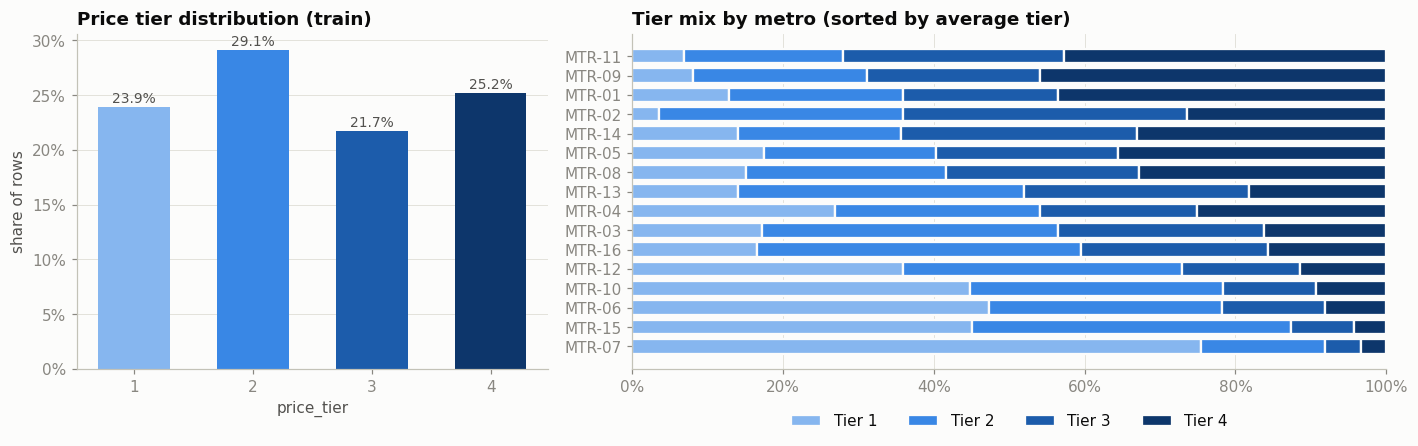

In [6]:
tier_share = train["price_tier"].value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(tier_share.index.astype(str), tier_share.values, color=TIER_COLORS, width=0.6)
label_bars(axes[0])
axes[0].set_title("Price tier distribution (train)")
axes[0].set_xlabel("price_tier"); 
axes[0].set_ylabel("share of rows")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].grid(axis="x", visible=False)

metro_mix = pd.crosstab(train["metro"], train["price_tier"], normalize="index")
metro_mix = metro_mix.loc[(metro_mix @ np.array([1, 2, 3, 4])).sort_values().index]
left = np.zeros(len(metro_mix))
for tier, color in zip(metro_mix.columns, TIER_COLORS):
    axes[1].barh(metro_mix.index, metro_mix[tier], left=left, color=color,
                 edgecolor="#fcfcfb", linewidth=1.5, label=f"Tier {tier}", height=0.75)
    left += metro_mix[tier].values
axes[1].set_title("Tier mix by metro (sorted by average tier)")
axes[1].set_xlim(0, 1); axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].grid(axis="y", visible=False)
axes[1].legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()

## Feature Distribution and Missing Value Analysis

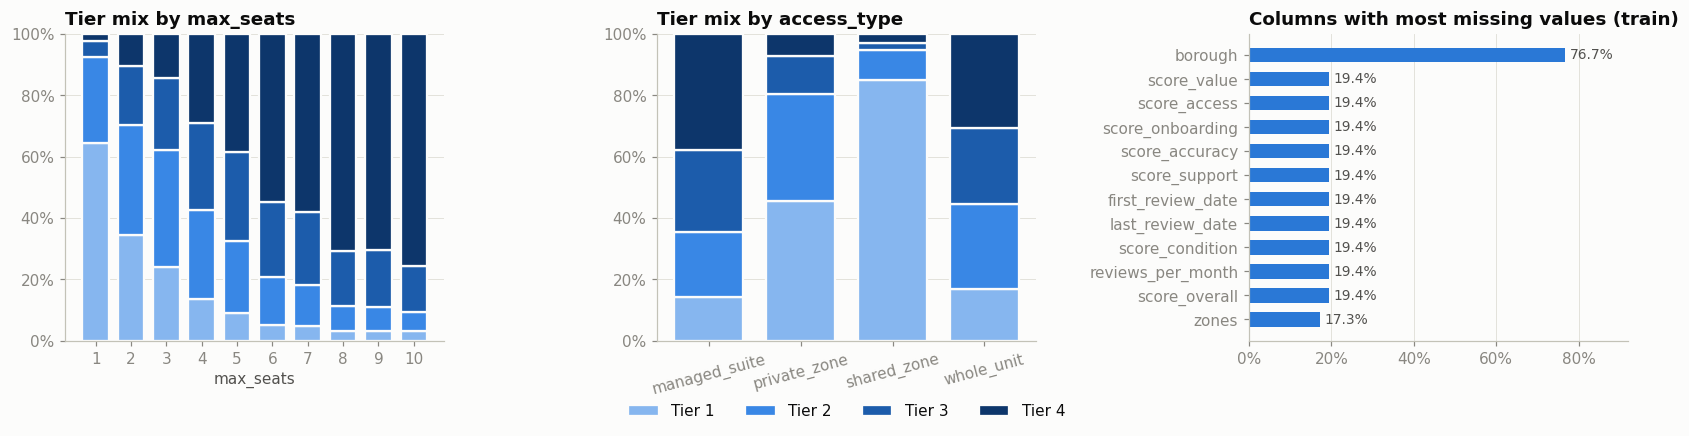

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

def stacked_mix(ax, key, title, order=None, max_levels=10):
    mix = pd.crosstab(train[key], train["price_tier"], normalize="index")
    counts = train[key].value_counts()
    mix = mix.loc[counts.head(max_levels).index]
    mix = mix.loc[order] if order is not None else mix.sort_index()
    bottom = np.zeros(len(mix))
    labels = mix.index.astype(str)
    for tier, color in zip(mix.columns, TIER_COLORS):
        ax.bar(labels, mix[tier], bottom=bottom, color=color, edgecolor="#fcfcfb",
               linewidth=1.5, label=f"Tier {tier}", width=0.75)
        bottom += mix[tier].values
    ax.set_title(title); ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", visible=False)

stacked_mix(axes[0], "max_seats", "Tier mix by max_seats")
axes[0].set_xlabel("max_seats")
stacked_mix(axes[1], "access_type", "Tier mix by access_type")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.3))

missing_share = train.isna().mean().sort_values(ascending=False)
missing_share = missing_share[missing_share > 0].head(12)[::-1]
axes[2].barh(missing_share.index, missing_share.values, color=C_BLUE, height=0.6)
label_bars(axes[2], horizontal=True)
axes[2].set_title("Columns with most missing values (train)")
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[2].set_xlim(0, missing_share.max() * 1.2); axes[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 7. Train/test overlap analysis

In [8]:
HOST_KEY = [
    "operator_ref", "operator_platform_age_years", "operator_platform_age_months",
    "operator_active_years", "operator_active_months",
    "operator_portfolio_size", "operator_metro_units", "metro",
]

def seen_share(col):
    seen = set(train[col].dropna().unique())
    test_values = test[col].dropna()
    return test_values.isin(seen).mean()

overlap = {col: seen_share(col) for col in ["operator_ref", "zone", "borough", "space_class", "metro"]}
print("Share of TEST rows whose value also appears in TRAIN:")
for col, value in overlap.items():
    print(f"{col:15s} {value:.3f}")

both = pd.concat([train[HOST_KEY], test[HOST_KEY]], ignore_index=True)
host_id_all = both.groupby(HOST_KEY, dropna=False).ngroup().values
host_train, host_test = host_id_all[:len(train)], host_id_all[len(train):]
identity_seen = np.isin(host_test, host_train).mean()

rng = np.random.RandomState(SEED)
fake_test = rng.rand(len(train)) < len(test) / (len(train) + len(test))
identity_seen_random = np.isin(host_train[fake_test], host_train[~fake_test]).mean()
name_codes = pd.factorize(train["operator_ref"])[0]
name_seen_random = np.isin(name_codes[fake_test], name_codes[~fake_test]).mean()

print(f"\nOperator NAME seen in train:      {overlap['operator_ref']:.3f}  (random split would give {name_seen_random:.3f})")
print(f"Operator IDENTITY seen in train:  {identity_seen:.3f}  (random split would give {identity_seen_random:.3f})")

CV_MODE = "group" if identity_seen < 0.05 else "random"
print("\nCV_MODE:", CV_MODE, "-> folds are grouped by operator identity" if CV_MODE == "group" else "")

Share of TEST rows whose value also appears in TRAIN:
operator_ref    0.664
zone            1.000
borough         1.000
space_class     1.000
metro           1.000

Operator NAME seen in train:      0.664  (random split would give 0.904)
Operator IDENTITY seen in train:  0.006  (random split would give 0.605)

CV_MODE: group -> folds are grouped by operator identity


## Visualizing Train-Test Operator Overlap

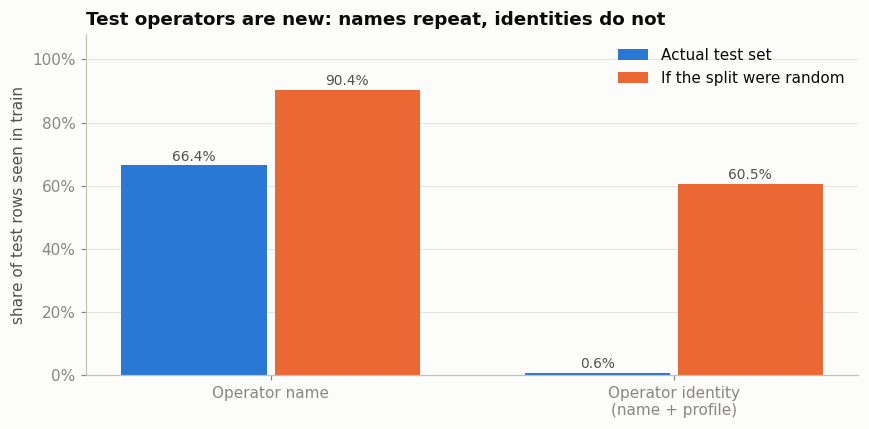

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = ["Operator name", "Operator identity\n(name + profile)"]
x = np.arange(2); width = 0.36
ax.bar(x - width / 2 - 0.01, [overlap["operator_ref"], identity_seen], width, color=C_BLUE, label="Actual test set")
ax.bar(x + width / 2 + 0.01, [name_seen_random, identity_seen_random], width, color=C_ORANGE, label="If the split were random")
label_bars(ax)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.08); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("share of test rows seen in train")
ax.set_title("Test operators are new: names repeat, identities do not")
ax.grid(axis="x", visible=False); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 8. Prepare combined train/test frame

In [10]:
n_train = len(train)
y0 = train["price_tier"].astype(int).values - 1
df = pd.concat([train.drop(columns=["price_tier"]), test], ignore_index=True)
n_all = len(df)
df["host_id"] = host_id_all

def safe_div(a, b):
    return a / b.replace(0, np.nan)

print("Combined frame:", df.shape, "| operator identities:", df["host_id"].nunique())

Combined frame: (394284, 60) | operator identities: 189666


## 9. Date based feature engineering

In [11]:
date_cols = ["snapshot_start_date", "snapshot_end_date", "first_review_date", "last_review_date"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

ref_date = df["snapshot_end_date"].max()
df["snapshot_duration_days"] = (df["snapshot_end_date"] - df["snapshot_start_date"]).dt.days
df["snap_start_ord"] = (df["snapshot_start_date"] - df["snapshot_start_date"].min()).dt.days
df["snap_start_month"] = df["snapshot_start_date"].dt.month
df["snap_start_dow"] = df["snapshot_start_date"].dt.dayofweek
df["days_since_first_review"] = (ref_date - df["first_review_date"]).dt.days
df["days_since_last_review"] = (ref_date - df["last_review_date"]).dt.days
df["review_history_days"] = (df["last_review_date"] - df["first_review_date"]).dt.days
df["review_rate_per_day"] = df["review_count"] / (df["review_history_days"].fillna(0) + 30)
df["has_reviews"] = (df["review_count"].fillna(0) > 0).astype(int)

print("Date features created.")

Date features created.


## 10. Rental Term - duration feature engineering

In [12]:
for col in ["max_term_days", "max_term_floor", "max_term_ceiling", "max_term_avg"]:
    df[f"{col}_extreme"] = (df[col] > 1125).astype(int)
    df[col] = df[col].clip(upper=1125)

term_cols = [
    "min_term_days", "max_term_days", "min_term_floor", "max_term_floor",
    "min_term_ceiling", "max_term_ceiling", "min_term_avg", "max_term_avg"
]
for col in term_cols:
    df[f"{col}_log"] = np.log1p(df[col].clip(lower=0))

df["term_days_range"] = df["max_term_days"] - df["min_term_days"]
df["term_floor_range"] = df["max_term_floor"] - df["min_term_floor"]
df["term_ceiling_range"] = df["max_term_ceiling"] - df["min_term_ceiling"]
df["term_avg_range"] = df["max_term_avg"] - df["min_term_avg"]
df["term_ratio"] = safe_div(df["max_term_days"], df["min_term_days"])
df["term_missing"] = df["max_term_days"].isna().astype(int)
df["max_term_is_365"] = (df["max_term_days"] == 365).astype(int)
df["max_term_is_1125"] = (df["max_term_days"] == 1125).astype(int)
df["min_term_is_1"] = (df["min_term_days"] == 1).astype(int)

print("Term features created.")

Term features created.


## 11. Capacity and availability feature engineering

In [13]:
df["seats_per_room"] = safe_div(df["max_seats"], df["utility_rooms"])
df["ws_per_seat"] = safe_div(df["workstations"], df["max_seats"])
df["ws_per_room"] = safe_div(df["workstations"], df["utility_rooms"])
df["seats_per_zones"] = safe_div(df["max_seats"], df["zones"])
df["seats_x_ws"] = df["max_seats"] * df["workstations"]
df["seats_x_rooms"] = df["max_seats"] * df["utility_rooms"]
df["load_per_seat"] = safe_div(df["booked_load"], df["max_seats"])
df["load_per_ws"] = safe_div(df["booked_load"], df["workstations"])

a, b, c_, d, e = [df[f"open_slots_{k}"] for k in "abcde"]
df["slots_a_b"] = safe_div(a, b)
df["slots_b_c"] = safe_div(b, c_)
df["slots_c_d"] = safe_div(c_, d)
df["slots_a_d"] = safe_div(a, d)
df["slots_e_d"] = safe_div(e, d)
df["slots_d_gap365"] = 365 - d
df["booked_load_ratio"] = safe_div(df["booked_load"], df["booked_load"] + e.fillna(0))
df["booked_vs_d"] = safe_div(df["booked_load"], d)

print("Capacity and availability features created.")

Capacity and availability features created.


## 12. Review and rating feature engineering

In [14]:
df["recent_review_ratio"] = safe_div(df["review_count_12m"], df["review_count"])
df["recent_30d_ratio"] = safe_div(df["review_count_30d"], df["review_count"])
df["prev_year_ratio"] = safe_div(df["review_count_prev_yr"], df["review_count"])
df["review_growth"] = safe_div(df["review_count_12m"], df["review_count_prev_yr"])

score_cols = [col for col in df.columns if col.startswith("score_")]
df["score_mean"] = df[score_cols].mean(axis=1)
df["score_min"] = df[score_cols].min(axis=1)
df["score_std"] = df[score_cols].std(axis=1)
df["score_range"] = df[score_cols].max(axis=1) - df[score_cols].min(axis=1)
df["n_scores_missing"] = df[score_cols].isna().sum(axis=1)
df["score_x_reviews"] = df["score_overall"] * np.log1p(df["review_count"])

miss_cols = [
    "borough", "reviews_per_month", "first_review_date", "last_review_date",
    "workstations", "utility_rooms", "operator_ref", "operator_certified"
] + score_cols
for col in miss_cols:
    if col in df.columns:
        df[f"{col}_missing"] = df[col].isna().astype(int)

print("Review and rating features created.")

Review and rating features created.


## 13. Operator profile feature engineering

In [15]:
df["platform_age_total_m"] = df["operator_platform_age_years"] * 12 + df["operator_platform_age_months"]
df["active_total_m"] = df["operator_active_years"] * 12 + df["operator_active_months"]
df["active_ratio"] = safe_div(df["active_total_m"], df["platform_age_total_m"])
df["operator_scale"] = df["operator_portfolio_size"].fillna(0) + df["operator_metro_units"].fillna(0)
df["metro_whole_ratio"] = safe_div(df["operator_metro_whole"], df["operator_metro_units"])
df["metro_shared_ratio"] = safe_div(df["operator_metro_shared"], df["operator_metro_units"])
df["metro_private_ratio"] = safe_div(df["operator_metro_private"], df["operator_metro_units"])
df["portfolio_per_metro"] = safe_div(df["operator_portfolio_size"], df["operator_metro_units"])

print("Operator features created.")

Operator features created.


## 14. Parse facilities and create facility indicators

In [16]:
def parse_fac(value):
    if not isinstance(value, str):
        return []
    try:
        parsed = json.loads(value)
    except Exception:
        try:
            parsed = ast.literal_eval(value)
        except Exception:
            return []
    return list(parsed) if isinstance(parsed, (list, tuple)) else []

fac_lists = df["facilities"].map(parse_fac)
df["facility_count"] = fac_lists.map(len)
df["facility_unique"] = fac_lists.map(lambda values: len(set(values)))
df["has_facilities"] = (df["facility_count"] > 0).astype(int)

mlb = MultiLabelBinarizer(sparse_output=True)
F = mlb.fit_transform(fac_lists).tocsc()
keep = np.asarray(F.sum(axis=0)).ravel() >= max(300 * SAMPLE_FRAC, 20)
F = F[:, keep]
fac_names = [f"fac_{name}" for name in np.array(mlb.classes_)[keep]]
fac_df = pd.DataFrame(F.toarray().astype(np.uint8), columns=fac_names)
df = pd.concat([df, fac_df], axis=1)

print("Facility indicator columns:", len(fac_names))
del F, fac_df, fac_lists
gc.collect()

Facility indicator columns: 141


0

## 15. Operator-portfolio features

Statistics over all listings of the same operator identity, computed on train + test together. No labels are used, so they are equally valid for the unseen operators in the test set.

In [17]:
host_group = df.groupby("host_id")
host_feats = pd.DataFrame(index=df.index)
host_feats["host_n"] = host_group["max_seats"].transform("size").astype("float32")
host_feats["host_n_vs_portfolio"] = host_feats["host_n"] / df["operator_portfolio_size"].replace(0, np.nan)

host_agg_cols = [
    "max_seats", "utility_rooms", "workstations", "facility_count", "score_overall",
    "min_term_days", "open_slots_d", "open_slots_a", "review_count", "booked_load",
    "reviews_per_month", "geo_lat", "geo_lon", "days_since_first_review"
]
for func in ["mean", "std"]:
    stats = host_group[host_agg_cols].transform(func).astype("float32")
    stats.columns = [f"host_{func}_{col}" for col in host_agg_cols]
    host_feats = pd.concat([host_feats, stats], axis=1)

for col in ["max_seats", "facility_count", "score_overall", "min_term_days", "open_slots_d", "review_count"]:
    host_feats[f"{col}_minus_host"] = df[col] - host_feats[f"host_mean_{col}"]

for col in ["zone", "space_class", "access_type"]:
    host_feats[f"host_nuniq_{col}"] = host_group[col].transform("nunique").astype("float32")

for value in df["access_type"].dropna().unique():
    host_feats[f"host_share_{value}"] = (
        (df["access_type"] == value).groupby(df["host_id"]).transform("mean").astype("float32")
    )

host_feats["host_seats_rank"] = host_group["max_seats"].rank(pct=True).astype("float32")
df = pd.concat([df, host_feats], axis=1)

print("Operator-portfolio features:", host_feats.shape[1])
del host_feats, host_group
gc.collect()

Operator-portfolio features: 44


0

## 16. Categorical and interaction features

In [18]:
cat_base = [
    "operator_class", "operator_certified", "operator_has_avatar",
    "operator_id_verified", "zone", "borough", "space_class", "access_type",
    "bookable", "compliance_status", "metro"
]
for col in cat_base:
    df[col] = df[col].fillna("__MISSING__").astype(str)

seats_str = df["max_seats"].fillna(-1).astype(int).astype(str)
rooms_str = df["utility_rooms"].fillna(-1).astype(int).astype(str)
df["zone__space_class"] = df["zone"] + "|" + df["space_class"]
df["metro__space_class"] = df["metro"] + "|" + df["space_class"]
df["borough__space_class"] = df["borough"] + "|" + df["space_class"]
df["space_class__access"] = df["space_class"] + "|" + df["access_type"]
df["space_class__seats"] = df["space_class"] + "|" + seats_str
df["zone__seats"] = df["zone"] + "|" + seats_str

cat_all = cat_base + [
    "zone__space_class", "metro__space_class", "borough__space_class",
    "space_class__access", "space_class__seats", "zone__seats"
]

# Location x configuration keys used for target encoding only
df["geo_cell"] = df["geo_lat"].astype(str) + "|" + df["geo_lon"].astype(str)
df["geo_cell2"] = (df["geo_lat"] * 20).round().astype(str) + "|" + (df["geo_lon"] * 20).round().astype(str)
df["geo_cell__access"] = df["geo_cell"] + "|" + df["access_type"]
df["zone__access"] = df["zone"] + "|" + df["access_type"]
df["zone__access__seats"] = df["zone"] + "|" + df["access_type"] + "|" + seats_str
df["metro__cfg"] = df["metro"] + "|" + df["access_type"] + "|" + seats_str + "|" + rooms_str
TE_ONLY = ["geo_cell", "geo_cell2", "geo_cell__access", "zone__access", "zone__access__seats", "metro__cfg"]

print("Categorical features:", len(cat_all), "| extra target-encoding keys:", len(TE_ONLY))

Categorical features: 17 | extra target-encoding keys: 6


## 17. Frequency encoding

In [19]:
for col in cat_all + TE_ONLY:
    df[f"{col}_freq"] = df[col].map(df[col].value_counts()).astype("float32") / n_all

print("Frequency encoding complete.")

Frequency encoding complete.


## 18. Group-relative numerical features

In [20]:
def add_group_stats(frame, key, cols, diff=True):
    group_means = frame.groupby(key)[cols].transform("mean")
    for col in cols:
        frame[f"{key}_mean_{col}"] = group_means[col].astype("float32")
        if diff:
            frame[f"{col}_minus_{key}"] = (frame[col] - group_means[col]).astype("float32")

stat_cols = [
    "max_seats", "workstations", "facility_count", "score_overall",
    "min_term_days", "booked_load", "open_slots_d", "zones"
]
for key in ["zone", "metro", "space_class", "zone__space_class"]:
    add_group_stats(df, key, stat_cols)

add_group_stats(df, "metro", ["geo_lat", "geo_lon"])
add_group_stats(df, "borough", ["geo_lat", "geo_lon", "max_seats", "facility_count"])

df["geo_dist_metro"] = np.sqrt(df["geo_lat_minus_metro"] ** 2 + df["geo_lon_minus_metro"] ** 2)
df["seats_rank_zone"] = df.groupby("zone")["max_seats"].rank(pct=True).astype("float32")

print("Group-relative features created.")

Group-relative features created.


## 19. Build model-ready matrices

In [21]:
host_all = df["host_id"].values
drop_cols = ["space_id", "facilities", "operator_ref", "host_id"] + date_cols
df = df.drop(columns=[col for col in drop_cols if col in df.columns])

CAT_COLS = cat_all + ["zone__access", "metro__cfg"]          # CatBoost native categoricals
HIGH_CARD = [col for col in cat_all if df[col].nunique() > 200]
LOW_CARD = [col for col in cat_all if col not in HIGH_CARD]  # LightGBM native categoricals
TE_COLS = [col for col in cat_all if df[col].nunique() > 10] + TE_ONLY

num_cols = [col for col in df.columns if col not in cat_all + TE_ONLY]
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan).astype("float32")

base_cb = df[num_cols + CAT_COLS].copy()
base_lgb = df[num_cols + LOW_CARD].copy()
for col in LOW_CARD:
    base_lgb[col] = base_lgb[col].astype("category")

print("Numeric features:", len(num_cols))
print("CatBoost categorical features:", len(CAT_COLS))
print("LightGBM categorical features:", len(LOW_CARD))
print("Target-encoded features:", TE_COLS)
print("base_cb:", base_cb.shape, "| base_lgb:", base_lgb.shape)

Numeric features: 409
CatBoost categorical features: 19
LightGBM categorical features: 11
Target-encoded features: ['zone', 'borough', 'space_class', 'metro', 'zone__space_class', 'metro__space_class', 'borough__space_class', 'space_class__access', 'space_class__seats', 'zone__seats', 'geo_cell', 'geo_cell2', 'geo_cell__access', 'zone__access', 'zone__access__seats', 'metro__cfg']
base_cb: (394284, 428) | base_lgb: (394284, 420)


## 20. Adversarial validation diagnostic

Adversarial AUC: 0.7306  (0.5 = train and test look alike)


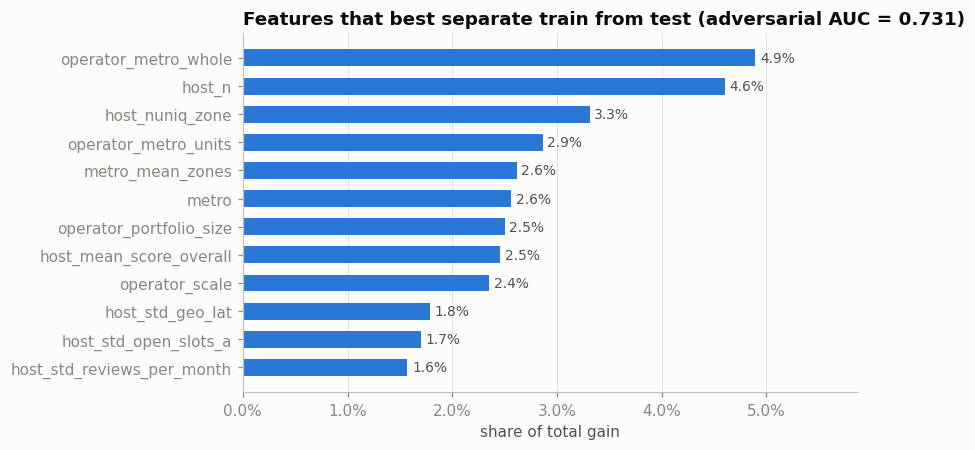

In [22]:
if RUN_ADV_VAL:
    rng = np.random.RandomState(SEED)
    adv_idx = rng.choice(n_all, size=min(n_all, 120_000), replace=False)
    Xa = base_lgb.iloc[adv_idx].reset_index(drop=True)
    ya = (adv_idx >= n_train).astype(int)
    cut = int(len(Xa) * 0.7)

    adv_model = lgb.train(
        dict(
            objective="binary", learning_rate=0.1, num_leaves=31,
            feature_fraction=0.5, verbosity=-1, seed=SEED
        ),
        lgb.Dataset(Xa.iloc[:cut], ya[:cut]),
        num_boost_round=150
    )
    adv_auc = roc_auc_score(ya[cut:], adv_model.predict(Xa.iloc[cut:]))
    print(f"Adversarial AUC: {adv_auc:.4f}  (0.5 = train and test look alike)")

    importance = pd.Series(
        adv_model.feature_importance("gain"), index=Xa.columns
    ).sort_values(ascending=False)
    adv_top = (importance / importance.sum()).head(12)

    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.barh(adv_top.index[::-1], adv_top.values[::-1], color=C_BLUE, height=0.6)
    label_bars(ax, horizontal=True)
    ax.set_title(f"Features that best separate train from test (adversarial AUC = {adv_auc:.3f})")
    ax.set_xlabel("share of total gain"); ax.set_xlim(0, adv_top.max() * 1.2)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

    del adv_model, Xa
    gc.collect()

## 21. Prepare labels and train/test indices

In [23]:
Y1h = np.eye(4)[y0]
all_idx = np.arange(n_train)
te_idx_all = np.arange(n_train, n_all)

print("Training rows:", len(all_idx), "| Test rows:", len(te_idx_all))

Training rows: 279746 | Test rows: 114538


## 22. Create validation folds

In [24]:
def make_splits(idx, n_splits, seed):
    """Stratified folds grouped by operator identity."""
    splitter = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)
    return list(splitter.split(idx, y0[idx], host_all[idx]))

splits = [
    (all_idx[train_pos], all_idx[valid_pos])
    for train_pos, valid_pos in make_splits(all_idx, N_FOLDS, SEED)
]

for fold_id, (train_idx, valid_idx) in enumerate(splits):
    unseen_fraction = (~np.isin(host_all[valid_idx], host_all[train_idx])).mean()
    print(
        f"Fold {fold_id + 1}: train={len(train_idx):,}, "
        f"valid={len(valid_idx):,}, unseen operators={unseen_fraction:.3f}"
    )

Fold 1: train=223,758, valid=55,988, unseen operators=1.000
Fold 2: train=224,586, valid=55,160, unseen operators=1.000
Fold 3: train=223,458, valid=56,288, unseen operators=1.000
Fold 4: train=224,462, valid=55,284, unseen operators=1.000
Fold 5: train=222,720, valid=57,026, unseen operators=1.000


## 23. Target-encoding helper functions

In [25]:
def inner_splits(train_idx, n_splits=4):
    return make_splits(train_idx, n_splits, SEED + 1)

def te_encode(cat_fit, y_fit, cat_apply, alpha=15.0):
    """Smoothed class-probability target encoding."""
    prior = y_fit.mean(axis=0)
    encoded_frame = pd.DataFrame(y_fit, columns=range(4))
    encoded_frame["key"] = np.asarray(cat_fit)
    grouped = encoded_frame.groupby("key").sum()
    counts = grouped.sum(axis=1)
    encoded = (grouped + alpha * prior).div(counts + alpha, axis=0)
    result = encoded.reindex(np.asarray(cat_apply)).to_numpy()
    return np.where(np.isnan(result), prior, result)

cat_arrays = {col: df[col].values for col in TE_COLS}
FAC_COLS = [col for col in df.columns if col.startswith("fac_")]
FAC = df[FAC_COLS].values.astype(np.float32)
facility_count_values = df["facility_count"].values.astype(np.float32)
FAC = np.c_[
    FAC,
    (facility_count_values - facility_count_values.mean())
    / (facility_count_values.std() + 1e-6)
]

## 24. Build leakage-safe supervised features

In [26]:
def build_supervised(train_idx, valid_idx):
    """Train rows use operator-grouped inner OOF encodings; validation/test use full outer-train encodings."""
    inner = inner_splits(train_idx)
    y_train = Y1h[train_idx]
    out_train, out_valid, out_test = {}, {}, {}
    tiers = np.array([1, 2, 3, 4])

    def put(prefix, pred_train, pred_valid, pred_test):
        for class_idx in range(4):
            out_train[f"{prefix}_{class_idx + 1}"] = pred_train[:, class_idx]
            out_valid[f"{prefix}_{class_idx + 1}"] = pred_valid[:, class_idx]
            out_test[f"{prefix}_{class_idx + 1}"] = pred_test[:, class_idx]

        out_train[f"{prefix}_exp"] = pred_train @ tiers
        out_valid[f"{prefix}_exp"] = pred_valid @ tiers
        out_test[f"{prefix}_exp"] = pred_test @ tiers

    for col in TE_COLS:
        values = cat_arrays[col]
        oof = np.zeros((len(train_idx), 4))

        for inner_train_pos, inner_valid_pos in inner:
            oof[inner_valid_pos] = te_encode(
                values[train_idx[inner_train_pos]],
                y_train[inner_train_pos],
                values[train_idx[inner_valid_pos]]
            )

        put(
            f"te_{col}",
            oof,
            te_encode(values[train_idx], y_train, values[valid_idx]),
            te_encode(values[train_idx], y_train, values[te_idx_all])
        )

    if USE_FAC_LR:
        def fit_predict_lr(x_fit, y_fit, x_apply):
            model = LogisticRegression(C=1.0, max_iter=150)
            model.fit(x_fit, y_fit)
            return model.predict_proba(x_apply)

        oof = np.zeros((len(train_idx), 4))
        for inner_train_pos, inner_valid_pos in inner:
            oof[inner_valid_pos] = fit_predict_lr(
                FAC[train_idx[inner_train_pos]],
                y0[train_idx[inner_train_pos]],
                FAC[train_idx[inner_valid_pos]]
            )

        put(
            "lrfac",
            oof,
            fit_predict_lr(FAC[train_idx], y0[train_idx], FAC[valid_idx]),
            fit_predict_lr(FAC[train_idx], y0[train_idx], FAC[te_idx_all])
        )

    return (
        pd.DataFrame(out_train).astype("float32"),
        pd.DataFrame(out_valid).astype("float32"),
        pd.DataFrame(out_test).astype("float32")
    )

## 25. Assemble model matrices

In [27]:
def assemble(base, train_idx, valid_idx, supervised_features):
    supervised_train, supervised_valid, supervised_test = supervised_features

    X_train = pd.concat([
        base.iloc[train_idx].reset_index(drop=True), supervised_train
    ], axis=1)
    X_valid = pd.concat([
        base.iloc[valid_idx].reset_index(drop=True), supervised_valid
    ], axis=1)
    X_test = pd.concat([
        base.iloc[te_idx_all].reset_index(drop=True), supervised_test
    ], axis=1)

    return X_train, X_valid, X_test

## 26. Model hyperparameters

In [28]:
LGB_PARAMS = dict(
    objective="multiclass",
    num_class=4,
    metric="multi_logloss",
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=50,
    feature_fraction=0.4,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambda_l2=10.0,
    cat_smooth=30,
    cat_l2=10,
    min_data_per_group=50,
    max_cat_to_onehot=8,
    verbosity=-1,
    seed=SEED,
    num_threads=-1,
)

## 27. LightGBM training function

In [29]:
def fit_lgb(X_train, y_train, X_valid, y_valid, X_test):
    train_data = lgb.Dataset(X_train, y_train)
    valid_data = lgb.Dataset(X_valid, y_valid, reference=train_data)

    model = lgb.train(
        LGB_PARAMS,
        train_data,
        num_boost_round=LGB_ROUNDS,
        valid_sets=[valid_data],
        callbacks=[
            lgb.early_stopping(100, verbose=False),
            lgb.log_evaluation(200)
        ]
    )

    valid_pred = model.predict(X_valid, num_iteration=model.best_iteration)
    test_pred = model.predict(X_test, num_iteration=model.best_iteration)
    gain = pd.Series(model.feature_importance("gain"), index=X_train.columns)
    return valid_pred, test_pred, model.best_iteration, gain

## 28. CatBoost training function

In [30]:
def fit_cb(X_train, y_train, X_valid, y_valid, X_test):
    def make_model(use_gpu):
        params = dict(
            loss_function="MultiClass",
            depth=8,
            l2_leaf_reg=6,
            random_seed=SEED,
            verbose=200,
            early_stopping_rounds=150
        )
        if use_gpu:
            params.update(
                task_type="GPU",
                iterations=CB_ITERS_GPU,
                learning_rate=0.06
            )
        else:
            params.update(
                task_type="CPU",
                iterations=CB_ITERS_CPU,
                learning_rate=0.1,
                max_ctr_complexity=1,
                border_count=128
            )
        return CatBoostClassifier(**params)

    try:
        model = make_model(GPU)
        model.fit(
            X_train, y_train,
            cat_features=CAT_COLS,
            eval_set=(X_valid, y_valid),
            use_best_model=True
        )
    except Exception as error:
        print("CatBoost GPU failed; falling back to CPU:", repr(error)[:200])
        model = make_model(False)
        model.fit(
            X_train, y_train,
            cat_features=CAT_COLS,
            eval_set=(X_valid, y_valid),
            use_best_model=True
        )

    return (
        model.predict_proba(X_valid),
        model.predict_proba(X_test),
        model.get_best_iteration()
    )

## 29. Initialize out-of-fold and test prediction arrays

In [31]:
oof_lgb = np.zeros((n_train, 4))
oof_cb = np.zeros((n_train, 4))
te_lgb = np.zeros((len(te_idx_all), 4))
te_cb = np.zeros((len(te_idx_all), 4))
fold_log = []
lgb_gain = None
training_start = time.time()

print("Prediction arrays initialized.")

Prediction arrays initialized.


## 30. Train both models across folds

In [ ]:
for fold, (train_idx, valid_idx) in enumerate(splits):
    elapsed_min = (time.time() - training_start) / 60
    print(f"\n{'=' * 60}")
    print(f"FOLD {fold + 1}/{N_FOLDS} | elapsed {elapsed_min:.1f} min")
    print(f"{'=' * 60}")

    supervised_features = build_supervised(train_idx, valid_idx)

    X_train, X_valid, X_test = assemble(
        base_lgb, train_idx, valid_idx, supervised_features
    )
    pred_valid, pred_test, best_iter, gain = fit_lgb(
        X_train, y0[train_idx], X_valid, y0[valid_idx], X_test
    )
    oof_lgb[valid_idx] = pred_valid
    te_lgb += pred_test / N_FOLDS
    lgb_gain = gain if lgb_gain is None else lgb_gain + gain
    acc_lgb = accuracy_score(y0[valid_idx], pred_valid.argmax(1))
    print(f"[LGB] fold accuracy={acc_lgb:.4f} | best iteration={best_iter}")

    X_train, X_valid, X_test = assemble(
        base_cb, train_idx, valid_idx, supervised_features
    )
    pred_valid, pred_test, best_iter = fit_cb(
        X_train, y0[train_idx], X_valid, y0[valid_idx], X_test
    )
    oof_cb[valid_idx] = pred_valid
    te_cb += pred_test / N_FOLDS
    acc_cb = accuracy_score(y0[valid_idx], pred_valid.argmax(1))
    print(f"[CB] fold accuracy={acc_cb:.4f} | best iteration={best_iter}")

    fold_log.append({"fold": fold + 1, "LightGBM": acc_lgb, "CatBoost": acc_cb})

    del X_train, X_valid, X_test, supervised_features
    gc.collect()

acc_oof_lgb = accuracy_score(y0, oof_lgb.argmax(1))
acc_oof_cb = accuracy_score(y0, oof_cb.argmax(1))
print("\nOOF accuracy - LightGBM:", round(acc_oof_lgb, 5))
print("OOF accuracy - CatBoost:", round(acc_oof_cb, 5))


FOLD 1/5 | elapsed 0.0 min
[200]	valid_0's multi_logloss: 0.661563
[400]	valid_0's multi_logloss: 0.640451
[600]	valid_0's multi_logloss: 0.633773
[800]	valid_0's multi_logloss: 0.631517
[1000]	valid_0's multi_logloss: 0.630959
[1200]	valid_0's multi_logloss: 0.631273
[LGB] fold accuracy=0.7256 | best iteration=1140
0:	learn: 1.3287944	test: 1.3287000	best: 1.3287000 (0)	total: 220ms	remaining: 11m
200:	learn: 0.6695667	test: 0.6961010	best: 0.6961010 (200)	total: 8.85s	remaining: 2m 3s
400:	learn: 0.6194251	test: 0.6710708	best: 0.6710708 (400)	total: 17.4s	remaining: 1m 52s


## 31. Fold scores and feature importance plots

In [ ]:
fold_frame = pd.DataFrame(fold_log)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})
x = np.arange(len(fold_frame)); width = 0.36
axes[0].bar(x - width / 2 - 0.01, fold_frame["LightGBM"], width, color=C_BLUE, label="LightGBM")
axes[0].bar(x + width / 2 + 0.01, fold_frame["CatBoost"], width, color=C_ORANGE, label="CatBoost")
label_bars(axes[0], fmt="{:.3f}")
low = fold_frame[["LightGBM", "CatBoost"]].values.min()
axes[0].set_ylim(low - 0.02, fold_frame[["LightGBM", "CatBoost"]].values.max() + 0.01)
axes[0].set_xticks(x); axes[0].set_xticklabels([f"Fold {f}" for f in fold_frame["fold"]])
axes[0].set_ylabel("validation accuracy (unseen operators)")
axes[0].set_title("Accuracy by fold (axis zoomed)")
axes[0].grid(axis="x", visible=False); axes[0].legend(loc="upper left", ncol=2)

top_gain = (lgb_gain / lgb_gain.sum()).sort_values(ascending=False).head(25)[::-1]
axes[1].barh(top_gain.index, top_gain.values, color=C_BLUE, height=0.65)
axes[1].set_title("LightGBM top 25 features (share of total gain)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 32. Compare blend weights on OOF predictions

In [ ]:
blend_results = []
for weight_lgb in np.arange(0.0, 1.001, 0.05):
    blended_oof = weight_lgb * oof_lgb + (1 - weight_lgb) * oof_cb
    blend_results.append({
        "lgb_weight": weight_lgb,
        "cb_weight": 1 - weight_lgb,
        "accuracy": accuracy_score(y0, blended_oof.argmax(1)),
        "logloss": log_loss(y0, blended_oof, labels=[0, 1, 2, 3])
    })

blend_results = pd.DataFrame(blend_results)
best_accuracy_row = blend_results.loc[blend_results["accuracy"].idxmax()]
best_logloss_row = blend_results.loc[blend_results["logloss"].idxmin()]

print("Best accuracy blend:")
print(best_accuracy_row)
print("\nBest log-loss blend:")
print(best_logloss_row)

if BLEND_OBJECTIVE == "accuracy":
    best_w = float(best_accuracy_row["lgb_weight"])
else:
    best_w = float(best_logloss_row["lgb_weight"])

oof_blend = best_w * oof_lgb + (1 - best_w) * oof_cb
te_blend = best_w * te_lgb + (1 - best_w) * te_cb
acc_blend = accuracy_score(y0, oof_blend.argmax(1))

print(
    f"Selected blend: LightGBM={best_w:.2f}, "
    f"CatBoost={1 - best_w:.2f}"
)
print("Selected blend OOF accuracy:", acc_blend)
print("Selected blend OOF log-loss:", log_loss(y0, oof_blend, labels=[0, 1, 2, 3]))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, color, title in [
    (axes[0], "accuracy", C_BLUE, "OOF accuracy vs LightGBM weight (higher is better)"),
    (axes[1], "logloss", C_ORANGE, "OOF log-loss vs LightGBM weight (lower is better)"),
]:
    ax.plot(blend_results["lgb_weight"], blend_results[metric], color=color, linewidth=2, marker="o", markersize=4)
    ax.axvline(best_w, color=MUTED, linewidth=1, linestyle="--")
    chosen = blend_results.loc[(blend_results["lgb_weight"] - best_w).abs().idxmin(), metric]
    ax.annotate(f"selected: {chosen:.4f}", (best_w, chosen), xytext=(8, -14 if metric == "accuracy" else 10),
                textcoords="offset points", fontsize=9, color="#52514e")
    ax.set_title(title); ax.set_xlabel("LightGBM weight (CatBoost = 1 - weight)")
plt.tight_layout(); plt.show()

## 33. Stage-2 operator-sibling stacker

In [ ]:
def sibling_block(prob, keys, prefix):
    """Mean probability / log-probability of the other rows sharing the same key."""
    key = pd.Series(np.asarray(keys))
    n = key.map(key.value_counts()).values.astype("float32")
    denom = np.maximum(n - 1, 1)[:, None]
    total = pd.DataFrame(prob).groupby(key.values).transform("sum").values
    others = (total - prob) / denom
    log_prob = np.log(np.clip(prob, 1e-6, 1))
    total_log = pd.DataFrame(log_prob).groupby(key.values).transform("sum").values
    others_log = (total_log - log_prob) / denom
    others[n == 1] = np.nan
    others_log[n == 1] = np.nan
    block = pd.DataFrame(
        np.c_[others, others @ np.arange(1, 5), others_log, n],
        columns=[f"{prefix}_p{k}" for k in range(1, 5)] + [f"{prefix}_exp"]
        + [f"{prefix}_logp{k}" for k in range(1, 5)] + [f"{prefix}_n"]
    )
    return block

STAGE2_RAW = [
    "max_seats", "utility_rooms", "workstations", "facility_count",
    "max_seats_minus_host", "facility_count_minus_host", "host_seats_rank"
]

def build_stage2(prob, rows):
    host_keys = host_all[rows]
    host_str = pd.Series(host_keys).astype(str).values
    frame = pd.DataFrame(prob, columns=["p1", "p2", "p3", "p4"])
    frame["exp"] = prob @ np.arange(1, 5)
    frame["margin"] = np.sort(prob, axis=1)[:, -1] - np.sort(prob, axis=1)[:, -2]
    frame = pd.concat([
        frame,
        sibling_block(prob, host_keys, "sib_host"),
        sibling_block(prob, host_str + "|" + df["zone"].values[rows], "sib_host_zone"),
        sibling_block(prob, host_str + "|" + df["access_type"].values[rows], "sib_host_access"),
    ], axis=1)
    frame["exp_minus_host"] = frame["exp"] - frame["sib_host_exp"]
    for col in STAGE2_RAW:
        frame[col] = df[col].values[rows]
    return frame.astype("float32")

STAGE2_PARAMS = dict(
    objective="multiclass", num_class=4, metric="multi_logloss", learning_rate=0.03, num_leaves=15,
    min_child_samples=200, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
    lambda_l2=5.0, verbosity=-1, seed=SEED, num_threads=-1
)

oof_final, te_final, acc_stage2 = oof_blend, te_blend, np.nan
if USE_STAGE2:
    X2_train = build_stage2(oof_blend, all_idx)
    X2_test = build_stage2(te_blend, te_idx_all)
    oof_stage2 = np.zeros((n_train, 4))
    te_stage2 = np.zeros((len(te_idx_all), 4))

    for train_idx, valid_idx in splits:
        train_data = lgb.Dataset(X2_train.iloc[train_idx], y0[train_idx])
        valid_data = lgb.Dataset(X2_train.iloc[valid_idx], y0[valid_idx], reference=train_data)
        model = lgb.train(
            STAGE2_PARAMS, train_data, num_boost_round=STAGE2_ROUNDS,
            valid_sets=[valid_data], callbacks=[lgb.early_stopping(50, verbose=False)]
        )
        oof_stage2[valid_idx] = model.predict(X2_train.iloc[valid_idx], num_iteration=model.best_iteration)
        te_stage2 += model.predict(X2_test, num_iteration=model.best_iteration) / N_FOLDS

    acc_stage2 = accuracy_score(y0, oof_stage2.argmax(1))
    print(f"Blend OOF accuracy:   {acc_blend:.5f} | log-loss {log_loss(y0, oof_blend, labels=[0, 1, 2, 3]):.5f}")
    print(f"Stage-2 OOF accuracy: {acc_stage2:.5f} | log-loss {log_loss(y0, oof_stage2, labels=[0, 1, 2, 3]):.5f}")

    if acc_stage2 > acc_blend:
        oof_final, te_final = oof_stage2, te_stage2
        print("Stage 2 improves OOF accuracy -> using stage-2 probabilities.")
    else:
        print("Stage 2 does not improve OOF accuracy -> keeping the blend.")

## 34. Tune class-wise probability multipliers

In [ ]:
def tune_class_weights(probabilities, labels, grid=np.arange(0.70, 1.61, 0.05), passes=3):
    weights = np.ones(4)
    best_accuracy = accuracy_score(labels, (probabilities * weights).argmax(1))

    for _ in range(passes):
        for class_idx in range(1, 4):
            for candidate in grid:
                candidate_weights = weights.copy()
                candidate_weights[class_idx] = candidate
                candidate_accuracy = accuracy_score(
                    labels, (probabilities * candidate_weights).argmax(1)
                )
                if candidate_accuracy > best_accuracy + 1e-6:
                    best_accuracy = candidate_accuracy
                    weights = candidate_weights

    return weights, best_accuracy

class_weights, weighted_accuracy = tune_class_weights(oof_final, y0)
print("Class weights:", np.round(class_weights, 2))
print("Weighted OOF accuracy:", round(weighted_accuracy, 5))

## 35. OOF evaluation

In [ ]:
final_oof_pred = (oof_final * class_weights).argmax(1) + 1
print(classification_report(y0 + 1, final_oof_pred, digits=4))
print("Confusion matrix:")
cm = confusion_matrix(y0 + 1, final_oof_pred)
print(cm)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.05, 1, 1.25]})

cm_norm = cm / cm.sum(axis=1, keepdims=True)
image = axes[0].imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f"{cm_norm[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center",
                     fontsize=9, color="#ffffff" if cm_norm[i, j] > 0.5 else INK)
axes[0].set_xticks(range(4)); axes[0].set_xticklabels([1, 2, 3, 4])
axes[0].set_yticks(range(4)); axes[0].set_yticklabels([1, 2, 3, 4])
axes[0].set_xlabel("predicted tier"); axes[0].set_ylabel("true tier")
axes[0].set_title("OOF confusion matrix (row %)"); axes[0].grid(False)

f1_per_class = f1_score(y0 + 1, final_oof_pred, average=None)
axes[1].bar(["1", "2", "3", "4"], f1_per_class, color=TIER_COLORS, width=0.6)
label_bars(axes[1], fmt="{:.3f}")
axes[1].set_ylim(0, 1); axes[1].set_xlabel("price_tier"); axes[1].set_title("OOF F1 by tier")
axes[1].grid(axis="x", visible=False)

stage_scores = pd.Series({
    "LightGBM": acc_oof_lgb, "CatBoost": acc_oof_cb, "Blend": acc_blend,
    "+ Stage 2": acc_stage2, "+ Class weights": weighted_accuracy,
}).dropna()
axes[2].barh(stage_scores.index[::-1], stage_scores.values[::-1], color=C_BLUE, height=0.55)
label_bars(axes[2], fmt="{:.4f}", horizontal=True)
axes[2].set_xlim(stage_scores.min() - 0.01, stage_scores.max() + 0.006)
axes[2].set_title("OOF accuracy by pipeline stage (axis zoomed)")
axes[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 36. Create submission predictions

In [ ]:
final_test_pred = (te_final * class_weights).argmax(1) + 1

id_col = sample_submission.columns[0]
target_col = sample_submission.columns[1]
submission = pd.DataFrame({
    id_col: test["space_id"].values,
    target_col: final_test_pred.astype(int)
})

print("Submission shape:", submission.shape)
print("Missing values:", int(submission.isnull().sum().sum()))
print("Duplicate IDs:", int(submission[id_col].duplicated().sum()))
print(
    "IDs match sample submission:",
    bool((submission[id_col].values == sample_submission[id_col].values).all())
)

## 37. Validate prediction distribution

In [ ]:
pred_share = submission[target_col].value_counts(normalize=True).reindex([1, 2, 3, 4]).fillna(0)
train_share = train["price_tier"].value_counts(normalize=True).reindex([1, 2, 3, 4])
oof_share = pd.Series(final_oof_pred).value_counts(normalize=True).reindex([1, 2, 3, 4]).fillna(0)

print("Predicted test distribution:")
print(pred_share.round(4))
print("\nTraining target distribution:")
print(train_share.round(4))
display(submission.head(10))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(4); width = 0.26
ax.bar(x - width - 0.01, train_share.values, width, color=C_BLUE, label="Train labels")
ax.bar(x, oof_share.values, width, color=C_ORANGE, label="OOF predictions")
ax.bar(x + width + 0.01, pred_share.values, width, color=C_AQUA, label="Test predictions")
label_bars(ax, fmt="{:.0%}")
ax.set_xticks(x); ax.set_xticklabels(["Tier 1", "Tier 2", "Tier 3", "Tier 4"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, max(train_share.max(), pred_share.max(), oof_share.max()) * 1.25)
ax.set_title("Tier distribution: labels vs predictions")
ax.grid(axis="x", visible=False); ax.legend(ncol=3, loc="upper center")
plt.tight_layout(); plt.show()

## 38. Save submission and reusable prediction files

In [ ]:
SAVE_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
submission_path = f"{SAVE_DIR}/submission.csv"
submission.to_csv(submission_path, index=False)

np.save(f"{SAVE_DIR}/oof_lgb.npy", oof_lgb)
np.save(f"{SAVE_DIR}/oof_cb.npy", oof_cb)
np.save(f"{SAVE_DIR}/test_lgb.npy", te_lgb)
np.save(f"{SAVE_DIR}/test_cb.npy", te_cb)
np.save(f"{SAVE_DIR}/oof_final.npy", oof_final)
np.save(f"{SAVE_DIR}/test_final.npy", te_final)

print("Saved submission:", submission_path)